### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 1
### Multi-Armed Bandit - Epsilon-Greedy Advertisement Selection

### Name: Yashvanth Karunakaran (23BAI1589)


### AIM:
Write a Python program to choose which advertisement to display using epsilon-greedy variants, and compute the regret over a minimum of 500 trials.

In this notebook, two epsilon decay strategies are implemented and compared:
1. Linear Decay
2. Exponential Decay

### Advertisement Bandit
10 advertisements with hidden click through probability such that agent does not know these values and must learn them through trial and error (1000 trials)

In [1]:
import numpy as np

ADS=10
TRIALS=1000

probs=np.random.uniform(0.05,0.95,ADS)

optimal_arm=np.argmax(probs)
optimal_reward=probs[optimal_arm]

### True Click Probabilities for each AD and Optimal AD

In [2]:
for i,ad in enumerate(probs):
    print(f"Ad {i}: Probability of reward = {ad:.2f}")

print(f"Optimal Ad: Ad {optimal_arm} with Probability of reward = {optimal_reward:.2f}")

Ad 0: Probability of reward = 0.11
Ad 1: Probability of reward = 0.45
Ad 2: Probability of reward = 0.93
Ad 3: Probability of reward = 0.41
Ad 4: Probability of reward = 0.60
Ad 5: Probability of reward = 0.65
Ad 6: Probability of reward = 0.67
Ad 7: Probability of reward = 0.27
Ad 8: Probability of reward = 0.16
Ad 9: Probability of reward = 0.11
Optimal Ad: Ad 2 with Probability of reward = 0.93


### Reward Function

When an ad is shown, a user either clicks (reward = 1) or doesn't (reward = 0), based on that ad's true probability.

In [3]:
def get_reward(ad_index):
    if np.random.rand() < probs[ad_index]:
        return 1
    return 0

### Epsilon Decay Strategies

Two decay variants are implemented:

#### Linear Decay:
eps_t = eps_start - ((eps_start - eps_end) / T) * t

#### Exponential Decay:
eps_t = eps_end + (eps_start - eps_end) * np.exp(-lam * t)


In [4]:
def linear_decay(t, T, eps_start=1.0, eps_end=0.01):
    return eps_start - ((eps_start - eps_end) / T) * t

def exponential_decay(t, eps_start=1.0, eps_end=0.01, lam=0.01):
    return eps_end + (eps_start - eps_end) * np.exp(-lam * t)

### Epsilon-Greedy Algorithm

At each trial:
With probability epsilon - explore (pick a random ad)
Otherwise - exploit (pick the ad with the highest current estimated value)

The value estimate is updated incrementally:
Q(A)_new = Q(A)_old + (1 / N(A)) × [R − Q(A)_old]


In [5]:
def epsilon_greedy(decay_func, n_trials=TRIALS, n_ads=ADS, **decay_params):

    Q = np.zeros(n_ads)
    N = np.zeros(n_ads)

    rewards = np.zeros(n_trials)
    regrets = np.zeros(n_trials)
    epsilons = np.zeros(n_trials)
    chosen_ads = np.zeros(n_trials, dtype=int)

    for t in range(n_trials):
        epsilon = decay_func(t, **decay_params)
        epsilons[t] = epsilon

        if np.random.rand() < epsilon:
            chosen_ad = np.random.randint(n_ads)
        else:
            chosen_ad = np.argmax(Q)

        reward = get_reward(chosen_ad)
        rewards[t] = reward
        regrets[t] = optimal_reward - reward
        chosen_ads[t] = chosen_ad

        N[chosen_ad] += 1
        Q[chosen_ad] += (reward - Q[chosen_ad]) / N[chosen_ad]
    
    cumulative_rewards = np.cumsum(rewards)
    cumulative_regrets = np.cumsum(regrets)

    return {"Q": Q, "N": N, "rewards": rewards, "regrets": regrets, "cumulative_rewards": cumulative_rewards, "cumulative_regrets": cumulative_regrets, "epsilons": epsilons, "chosen_ads": chosen_ads}

### Linear Decay Result

In [6]:
linear_results = epsilon_greedy(linear_decay, T=TRIALS, n_ads=ADS, eps_start=1.0, eps_end=0.01)

print(f"Total Reward: {linear_results['cumulative_rewards'][-1]}, Total Regret: {linear_results['cumulative_regrets'][-1]}\n")
print(f"Final Q-values: {linear_results['Q']}\n")
print(f"Number of times each ad was chosen: {linear_results['N']}\n")
print(f"Final Epsilon: {linear_results['epsilons'][-1]}\n")
print("Actual Probabilities of Ads: ", probs)

Total Reward: 684.0, Total Regret: 248.89235296390768

Final Q-values: [0.15       0.42857143 0.93490054 0.34693878 0.53448276 0.75
 0.61538462 0.3        0.13793103 0.1372549 ]

Number of times each ad was chosen: [ 40.  49. 553.  49.  58.  40.  52.  50.  58.  51.]

Final Epsilon: 0.010990000000000055

Actual Probabilities of Ads:  [0.11384308 0.445817   0.93289235 0.41322667 0.59931804 0.650607
 0.66686942 0.27275773 0.15586158 0.10825478]


### Exponential Decay Result

In [7]:
exponential_results = epsilon_greedy(exponential_decay, eps_start=1.0, eps_end=0.01, lam=0.01)

print(f"Total Reward: {exponential_results['cumulative_rewards'][-1]}, Total Regret: {exponential_results['cumulative_regrets'][-1]}\n")
print(f"Final Q-values: {exponential_results['Q']}\n")
print(f"Number of times each ad was chosen: {exponential_results['N']}\n")
print(f"Final Epsilon: {exponential_results['epsilons'][-1]}\n")
print("Actual Probabilities of Ads: ", probs)

Total Reward: 869.0, Total Regret: 63.892352963911435

Final Q-values: [0.21428571 0.55555556 0.91933702 0.35294118 0.5        0.83333333
 0.83333333 0.36842105 0.09090909 0.2       ]

Number of times each ad was chosen: [ 14.   9. 905.  17.   8.   6.   6.  19.  11.   5.]

Final Epsilon: 0.010045397644575786

Actual Probabilities of Ads:  [0.11384308 0.445817   0.93289235 0.41322667 0.59931804 0.650607
 0.66686942 0.27275773 0.15586158 0.10825478]


In [8]:
import pandas as pd

summary_df = pd.DataFrame({
    "Strategy": ["Linear Decay", "Exponential Decay"],
    "Total Reward": [
        linear_results["cumulative_rewards"][-1],
        exponential_results["cumulative_rewards"][-1]
    ],
    "Total Regret": [
        linear_results["cumulative_regrets"][-1],
        exponential_results["cumulative_regrets"][-1]
    ],
    "Final Epsilon": [
        linear_results["epsilons"][-1],
        exponential_results["epsilons"][-1]
    ]
})

summary_df

,Strategy,Total Reward,Total Regret,Final Epsilon
0,Linear Decay,684.0,248.892353,0.010990
1,Exponential Decay,869.0,63.892353,0.010045


In [9]:
adwise_df = pd.DataFrame({
    "Ad": np.arange(ADS),
    "True Probability": probs,
    "Linear Q": linear_results["Q"],
    "Exponential Q": exponential_results["Q"],
    "Linear N": linear_results["N"],
    "Exponential N": exponential_results["N"]
})

adwise_df

,Ad,True Probability,Linear Q,Exponential Q,Linear N,Exponential N
0,0,0.113843,0.150000,0.214286,40.0,14.0
1,1,0.445817,0.428571,0.555556,49.0,9.0
2,2,0.932892,0.934901,0.919337,553.0,905.0
3,3,0.413227,0.346939,0.352941,49.0,17.0
4,4,0.599318,0.534483,0.500000,58.0,8.0
5,5,0.650607,0.750000,0.833333,40.0,6.0
6,6,0.666869,0.615385,0.833333,52.0,6.0
7,7,0.272758,0.300000,0.368421,50.0,19.0
8,8,0.155862,0.137931,0.090909,58.0,11.0
9,9,0.108255,0.137255,0.200000,51.0,5.0


### Plottings

### Epsilon Decay Over Time

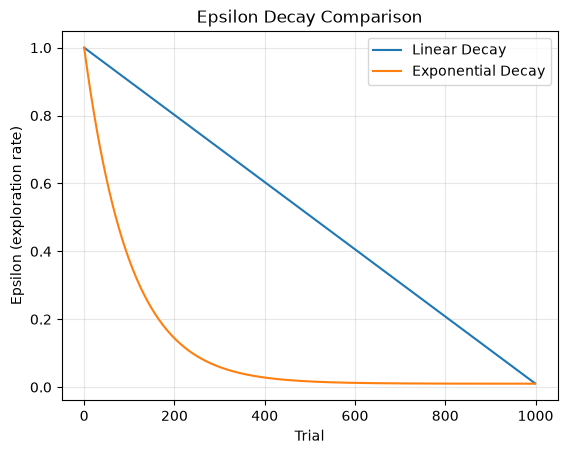

In [10]:
import matplotlib.pyplot as plt

plt.plot(linear_results['epsilons'], label='Linear Decay')
plt.plot(exponential_results['epsilons'], label='Exponential Decay')
plt.xlabel('Trial')
plt.ylabel('Epsilon (exploration rate)')
plt.title('Epsilon Decay Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Cummulative Regret Comparison

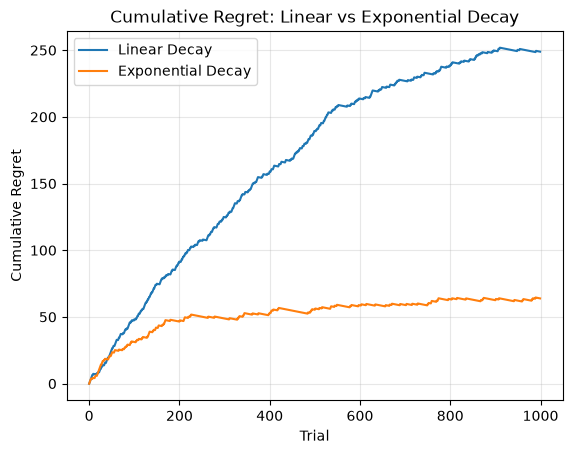

In [11]:
plt.plot(linear_results['cumulative_regrets'], label='Linear Decay')
plt.plot(exponential_results['cumulative_regrets'], label='Exponential Decay')
plt.xlabel('Trial')
plt.ylabel('Cumulative Regret')
plt.title('Cumulative Regret: Linear vs Exponential Decay')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Average Reward Over Time (Rolling Average Window 50)

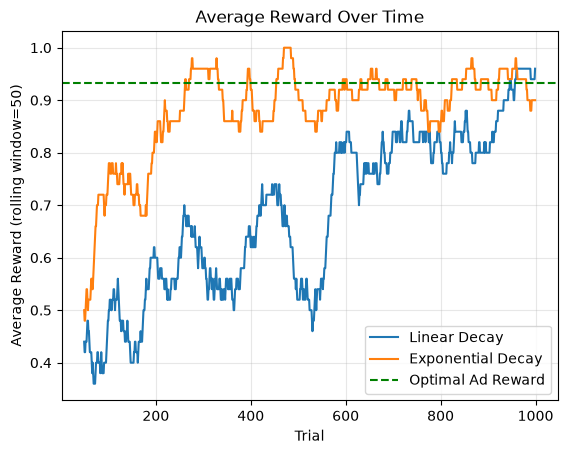

In [12]:
window = 50
avg_reward_linear = pd.Series(linear_results['rewards']).rolling(window).mean()
avg_reward_exp = pd.Series(exponential_results['rewards']).rolling(window).mean()

plt.plot(avg_reward_linear, label='Linear Decay')
plt.plot(avg_reward_exp, label='Exponential Decay')
plt.axhline(optimal_reward, color='green', linestyle='--', label='Optimal Ad Reward')
plt.xlabel('Trial')
plt.ylabel(f'Average Reward (rolling window={window})')
plt.title('Average Reward Over Time')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Number of Time each AD was chosen

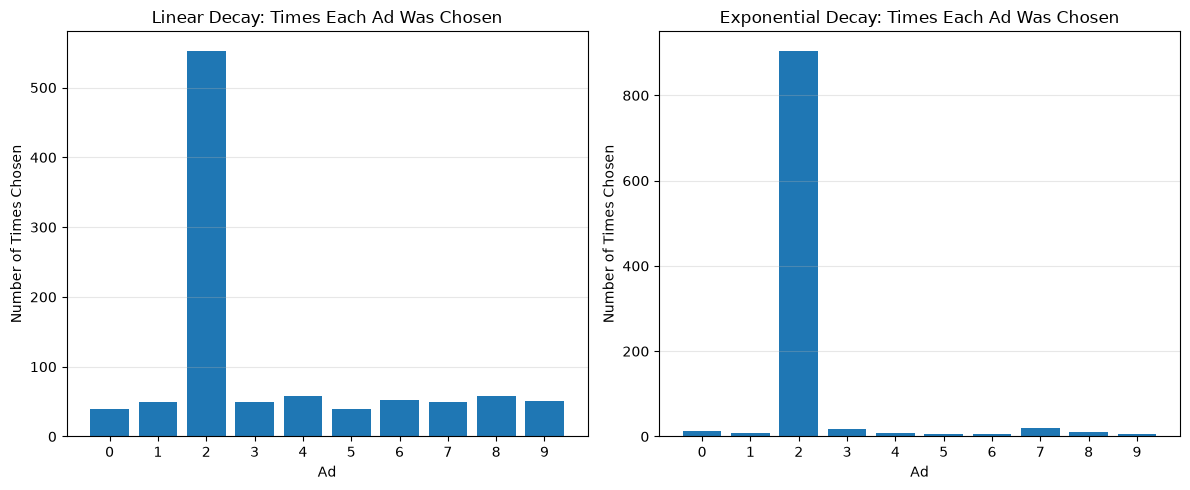

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(range(ADS), linear_results['N'])
plt.xlabel('Ad')
plt.ylabel('Number of Times Chosen')
plt.title('Linear Decay: Times Each Ad Was Chosen')
plt.xticks(range(ADS))
plt.grid(alpha=0.3, axis='y')

plt.subplot(1, 2, 2)
plt.bar(range(ADS), exponential_results['N'])
plt.xlabel('Ad')
plt.ylabel('Number of Times Chosen')
plt.title('Exponential Decay: Times Each Ad Was Chosen')
plt.xticks(range(ADS))
plt.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Estimated Q-values vs True Probabilities

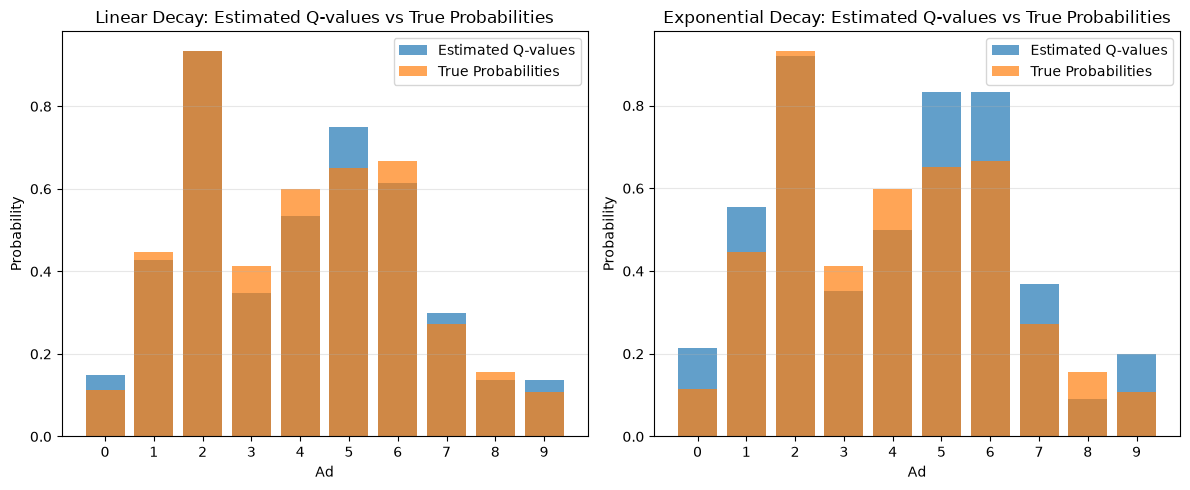

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(range(ADS), linear_results['Q'], label='Estimated Q-values', alpha=0.7)
plt.bar(range(ADS), probs, label='True Probabilities', alpha=0.7)
plt.xlabel('Ad')
plt.ylabel('Probability')
plt.title('Linear Decay: Estimated Q-values vs True Probabilities')
plt.xticks(range(ADS))
plt.legend()
plt.grid(alpha=0.3, axis='y')

plt.subplot(1, 2, 2)
plt.bar(range(ADS), exponential_results['Q'], label='Estimated Q-values', alpha=0.7)
plt.bar(range(ADS), probs, label='True Probabilities', alpha=0.7)
plt.xlabel('Ad')
plt.ylabel('Probability')
plt.title('Exponential Decay: Estimated Q-values vs True Probabilities')
plt.xticks(range(ADS))
plt.legend()
plt.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Inference:
1. Both the Linear Decay and Exponential Decay epsilon-greedy strategies were able to
  identify the advertisement with the highest true click-through probability over the course
  of 1000 trials, but they differ in how quickly and how 
  consistently they converge.

2. Exponential Decay reduces the exploration rate (epsilon) sharply in the early trials
  and then flattens out, meaning the agent stops exploring random ads relatively quickly and
  starts exploiting its best-known ad sooner. This generally leads to lower cumulative regret
  in the long run, since fewer trials are "wasted" on random exploration once a good estimate
  of the best ad has been found.

3. Linear Decay reduces epsilon at a constant, steady rate across all trials. This means the
  agent continues exploring for longer in absolute terms, which can slightly increase cumulative
  regret compared to exponential decay, but it also reduces the risk of prematurely committing to
  a suboptimal ad if the early estimates were noisy.


### Conclusion
Exponential decay tends to be more sample-efficient (lower regret, faster
convergence) in this experiment, while linear decay explores more conservatively for longer.